# Italy - National Market Analysis

<!-- STRUCTURE
1. [Initial setup](#1-initial-setup)  
    1.1. [Dataset loading and timespan definition ](#11-dataset-loading-and-timespan-definition)  
    1.2. [Variables building](#12-variables-building)  
2. [Data Analysis](#2-data-analysis)  
    2.1. [Descriptive statistics](#21-descriptive-statistics)  
    2.2. [Distribution analysis](#22-distribution-analysis)  
    2.3. [Time series analysis](#23-time-series-analysis)  
    2.4. [Relationship analysis](#24-relationship-analysis)  
    2.5. [Renewable penetration and market regimes](#25-renewable-penetration-and-market-regimes)  
-->

# 1. Initial setup 

## 1.1. Imports and configuration

In [161]:
# import libraries
import pandas as pd
import numpy as np
import warnings
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go 
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr

# filter User and Filter Warnings for privacy matters
warnings.simplefilter(action='ignore', category=UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

In [162]:
# user input data --> user parameters configuration
zone = 'IT'
price_col_name = 'PUN'
load_col_name = 'National Load'
timezone = 'Europe/Rome'
start = '2016-01-01 00:00'
end = '2026-06-30 23:00'

## 1.2. Dataset loading and timespan definition

In [163]:
# define dataset folder path
dataset_path = Path('../dataset/filled')

# read dataset
df = pd.read_csv(dataset_path / f'{zone}.csv')

# fix datetime timezones 
df['datetime_UTC'] = pd.to_datetime(df['datetime_UTC'], utc=True)
df['datetime_local'] = pd.to_datetime(df['datetime_local'], utc=True)
df['datetime_local'] = df['datetime_local'].dt.tz_convert(f'{timezone}')

In [164]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,Energy storage,Other renewable,Geothermal_source
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,1259.00,287.00,9112.00,0.00,45.0,203.00,0.00,NaN,NaN,ENTSO-E
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,1163.00,81.00,9324.00,1.00,46.0,218.00,0.00,NaN,NaN,ENTSO-E
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,1089.00,20.00,8739.00,0.00,44.0,267.00,0.00,NaN,NaN,ENTSO-E
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,1010.00,20.00,8195.00,0.00,39.0,227.00,0.00,NaN,NaN,ENTSO-E
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,988.00,20.00,7876.00,0.00,44.0,212.00,0.00,NaN,NaN,ENTSO-E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,4189.75,1167.25,1709.00,1755.75,NaN,1780.75,1.00,1148.333333,NaN,ENTSO-E
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,4343.25,1209.75,1767.00,252.00,NaN,2076.50,5.75,1273.750000,NaN,ENTSO-E
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,4252.50,982.50,1793.50,0.50,NaN,2587.75,5.50,830.333333,NaN,ENTSO-E
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,3931.75,618.00,1792.25,0.00,NaN,2068.75,1.25,241.750000,NaN,ENTSO-E


In [165]:
# filter dataset by period of time
start_date = pd.Timestamp(
    f'{start}',
    tz='Europe/Rome'
)

end_date = pd.Timestamp(
    f'{end}',
    tz='Europe/Rome'
)

df = df[
    df['datetime_local'].between(start_date, end_date)
].copy()

In [166]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,Energy storage,Other renewable,Geothermal_source
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,1259.00,287.00,9112.00,0.00,45.0,203.00,0.00,NaN,NaN,ENTSO-E
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,1163.00,81.00,9324.00,1.00,46.0,218.00,0.00,NaN,NaN,ENTSO-E
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,1089.00,20.00,8739.00,0.00,44.0,267.00,0.00,NaN,NaN,ENTSO-E
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,1010.00,20.00,8195.00,0.00,39.0,227.00,0.00,NaN,NaN,ENTSO-E
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,988.00,20.00,7876.00,0.00,44.0,212.00,0.00,NaN,NaN,ENTSO-E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,4189.75,1167.25,1709.00,1755.75,NaN,1780.75,1.00,1148.333333,NaN,ENTSO-E
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,4343.25,1209.75,1767.00,252.00,NaN,2076.50,5.75,1273.750000,NaN,ENTSO-E
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,4252.50,982.50,1793.50,0.50,NaN,2587.75,5.50,830.333333,NaN,ENTSO-E
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,3931.75,618.00,1792.25,0.00,NaN,2068.75,1.25,241.750000,NaN,ENTSO-E


## 1.3. Variables building

In [167]:
df.columns.tolist()

['datetime_UTC',
 'datetime_local',
 'local_hour',
 'PUN',
 'National Load',
 'Biomass',
 'Fossil Coal-derived gas',
 'Fossil Gas',
 'Fossil Hard coal',
 'Fossil Oil',
 'Geothermal',
 'Hydro Pumped Storage',
 'Hydro Run-of-river and poundage',
 'Hydro Water Reservoir',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Wind Offshore',
 'Energy storage',
 'Other renewable',
 'Geothermal_source']

In [168]:
# report amount of missing values
missing = df.isna().sum()
missing = missing[missing > 0]

print('\n--- MISSING VALUES ---')
print(missing)


--- MISSING VALUES ---
Fossil Coal-derived gas      598
Fossil Gas                   145
Fossil Hard coal             500
Fossil Oil                   755
Geothermal                    48
Hydro Pumped Storage        7298
Hydro Water Reservoir         24
Other                        288
Waste                       2351
Wind Onshore                   8
Wind Offshore                864
Energy storage             82821
Other renewable            87506
dtype: int64


Main variables:
- Total_Generation_approx: broader approximate generation aggregate
- Total_Generation_core: generation from selected core technologies
- RES_core: selected renewable generation
- RES_share_core: share of RES within the selected core generation mix
- Residual_Demand_core: national load minus RES_core

In [169]:
# map technology groups
wind = ['Wind Onshore', 'Wind Offshore']
hydro = ['Hydro Run-of-river and poundage', 'Hydro Water Reservoir']

res_core = [
    'Biomass',
    'Geothermal',
    'Hydro Run-of-river and poundage',
    'Hydro Water Reservoir',
    'Wind Onshore', 
    'Wind Offshore',
    'Solar'
]

fossil = [
    'Fossil Coal-derived gas', 
    'Fossil Gas', 
    'Fossil Hard coal', 
    'Fossil Oil'
]

Broader approximate generation aggregate.  
Energy Storage, Hydro Pumped Storage and Other renewable are excluded.  
Other and Waste are retained, although their classification and/or data coverage require caution.

In [170]:
generation_approx_cols = [
    'Biomass',
    'Fossil Coal-derived gas',
    'Fossil Gas',
    'Fossil Hard coal',
    'Fossil Oil',
    'Geothermal',
    'Hydro Run-of-river and poundage',
    'Hydro Water Reservoir',
    'Other',
    'Solar',
    'Waste',
    'Wind Onshore',
    'Wind Offshore'
]

# core aggregate: only selected RES and fossil technologies
total_gen_core_cols = list(dict.fromkeys(res_core + fossil))

# check that all expected source columns exist
required_cols = list(dict.fromkeys(
    generation_approx_cols + total_gen_core_cols
))

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise KeyError(f'Missing generation columns: {missing_cols}')

In [171]:
# aggregate generation by technology
df['Hydro'] = df[hydro].sum(axis=1, min_count=len(hydro))
df['Wind'] = df[wind].sum(axis=1, min_count=len(wind))
df['Fossil'] = df[fossil].sum(axis=1, min_count=len(fossil))
df['RES_core'] = df[res_core].sum(
    axis=1,
    min_count=len(res_core)
)

In [172]:
# approximate broader generation total - value is computed only when all included components are observed
df['Total_Generation_approx'] = df[generation_approx_cols].sum(
    axis=1,
    min_count=len(generation_approx_cols)
)

df['Generation_approx_missing_components'] = (
    df[generation_approx_cols].isna().sum(axis=1)
)

df['Generation_approx_completeness_pct'] = (
    df[generation_approx_cols].notna().mean(axis=1) * 100
)

In [173]:
# core generation total
df['Total_Generation_core'] = df[total_gen_core_cols].sum(
    axis=1,
    min_count=len(total_gen_core_cols)
)

df['Core_Generation_Missing_Components'] = (
    df[total_gen_core_cols].isna().sum(axis=1)
)

df['Core_Generation_Completeness_pct'] = (
    df[total_gen_core_cols].notna().mean(axis=1) * 100
)

In [174]:
# core renewable share and residual demand
df['RES_share_core'] = (
    df['RES_core'] / df['Total_Generation_core']
)

df['Residual_Demand_core'] = (
    df['National Load'] - df['RES_core']
)

In [175]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Fossil,RES_core,Total_Generation_approx,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,8057.00,2675.0,19889.0,0,100.000000,10732.00,0,100.0,0.249255,21252.233
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,7513.00,2385.0,19268.0,0,100.000000,9898.00,0,100.0,0.240958,20132.279
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,6985.00,2299.0,18067.0,0,100.000000,9284.00,0,100.0,0.247630,19055.678
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,6710.00,2178.0,17122.0,0,100.000000,8888.00,0,100.0,0.245050,18041.874
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,6251.00,2142.0,16313.0,0,100.000000,8393.00,0,100.0,0.255213,17087.221
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,28160.25,10160.0,NaN,1,92.307692,38320.25,0,100.0,0.265134,38277.300
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,28657.00,9153.5,NaN,1,92.307692,37810.50,0,100.0,0.242089,38230.000
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,28308.75,9099.5,NaN,1,92.307692,37408.25,0,100.0,0.243248,36851.600
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,28131.25,7885.0,NaN,1,92.307692,36016.25,0,100.0,0.218929,35319.200


## 1.4. Market regimes and calendar variables

**Market regimes** are predefined analytical periods, while **calendar variables** control for recurring hourly, weekly and seasonal patterns.

| Name          | From       | To         | Description |
|---------------|------------|------------|-------------|
| Pre_crises    | 2016       | 2020-03-08 | Market before the energy crisis
| Demand_crisis | 2020-03-09 | 2021-06-30 | COVID pandemic demand crisis
| Supply crisis | 2021-07-01 | 2023-04-30 | European gas-market tightening, intensified by Russia's invasion of Ukraine
| Post_crises   | 2023-05-01 | 2026       | Current market

In [176]:
# reconstruct local time from the canonical UTC timestamp
df['datetime_UTC'] = pd.to_datetime(
    df['datetime_UTC'],
    utc=True
)

df['datetime_local'] = (
    df['datetime_UTC'].dt.tz_convert(timezone)
)

# calendar variables
df['local_hour'] = df['datetime_local'].dt.hour
df['day_of_week'] = df['datetime_local'].dt.dayofweek
df['local_month'] = df['datetime_local'].dt.month

# market regime cutoffs
cut_demand = pd.Timestamp(
    '2020-03-09 00:00', tz=timezone
)
cut_supply = pd.Timestamp(
    '2021-07-01 00:00', tz=timezone
)
cut_post = pd.Timestamp(
    '2023-05-01 00:00', tz=timezone
)

conditions = [
    df['datetime_local'] < cut_demand,
    df['datetime_local'] < cut_supply,
    df['datetime_local'] < cut_post
]

choices = [
    'Pre_crises',
    'Demand_crisis',
    'Supply_crisis'
]

df['Period'] = np.select(
    conditions,
    choices,
    default='Post_crises'
)

# define the category order for readability
period_categories = [
    'Pre_crises',
    'Demand_crisis',
    'Supply_crisis',
    'Post_crises'
]

df['Period'] = pd.Categorical(
    df['Period'],
    categories=period_categories,
    ordered=True
)

# check period coverage
period_summary = (
    df.groupby('Period', observed=True)
    .agg(
        first_date=('datetime_local', 'min'),
        last_date=('datetime_local', 'max'),
        observations=('datetime_local', 'size')
    )
)

period_summary


,first_date,last_date,observations
Period,,,
Pre_crises,2016-01-01 00:00:00+01:00,2020-03-08 23:00:00+01:00,36696
Demand_crisis,2020-03-09 00:00:00+01:00,2021-06-30 23:00:00+02:00,11495
Supply_crisis,2021-07-01 00:00:00+02:00,2023-04-30 23:00:00+02:00,16056
Post_crises,2023-05-01 00:00:00+02:00,2026-06-30 23:00:00+02:00,27768


In [177]:
df

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core,day_of_week,local_month,Period
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,0,100.000000,10732.00,0,100.0,0.249255,21252.233,4,1,Pre_crises
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,0,100.000000,9898.00,0,100.0,0.240958,20132.279,4,1,Pre_crises
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,0,100.000000,9284.00,0,100.0,0.247630,19055.678,4,1,Pre_crises
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,0,100.000000,8888.00,0,100.0,0.245050,18041.874,4,1,Pre_crises
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,0,100.000000,8393.00,0,100.0,0.255213,17087.221,4,1,Pre_crises
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,1,92.307692,38320.25,0,100.0,0.265134,38277.300,1,6,Post_crises
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,1,92.307692,37810.50,0,100.0,0.242089,38230.000,1,6,Post_crises
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,1,92.307692,37408.25,0,100.0,0.243248,36851.600,1,6,Post_crises
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,1,92.307692,36016.25,0,100.0,0.218929,35319.200,1,6,Post_crises


# 2. Exploratory Data Analysis

## 2.1. Descriptive statistics
Descriptive statistics includes measures of central tendency, dispersion and distribution shape through the ten-years time span.

In [178]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92015 entries, 0 to 92014
Data columns (total 37 columns):
 #   Column                                Non-Null Count  Dtype                      
---  ------                                --------------  -----                      
 0   datetime_UTC                          92015 non-null  datetime64[us, UTC]        
 1   datetime_local                        92015 non-null  datetime64[us, Europe/Rome]
 2   local_hour                            92015 non-null  int32                      
 3   PUN                                   92015 non-null  float64                    
 4   National Load                         92015 non-null  float64                    
 5   Biomass                               92015 non-null  float64                    
 6   Fossil Coal-derived gas               91417 non-null  float64                    
 7   Fossil Gas                            91870 non-null  float64                    
 8   Fossil Hard coal           

In [179]:
df.describe()

,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,Geothermal,Hydro Pumped Storage,...,Total_Generation_approx,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core,day_of_week,local_month
count,92015.000000,92015.000000,92015.000000,92015.000000,91417.000000,91870.000000,91515.000000,91260.000000,91967.000000,84717.000000,...,86609.000000,92015.000000,92015.000000,89097.000000,92015.000000,92015.000000,89097.000000,91071.000000,92015.000000,92015.000000
mean,11.500103,104.148082,32163.483543,532.873923,471.557971,10922.962507,1521.482437,140.167615,631.168269,419.655976,...,27585.878803,0.060653,99.533437,23381.962651,0.031973,99.709336,0.447665,21804.145362,3.000228,6.380818
std,6.922191,90.169382,6709.339648,165.115113,228.485317,5145.218856,1066.666352,163.217786,31.156868,552.966412,...,6928.194236,0.246533,1.896411,6702.527252,0.177406,1.612779,0.149668,6126.404140,2.000454,3.446760
min,0.000000,0.000000,16272.977000,151.000000,0.000000,1051.500000,0.000000,0.000000,460.500000,0.000000,...,11063.750000,0.000000,84.615385,6326.000000,0.000000,81.818182,0.111004,-1164.305000,0.000000,1.000000
25%,6.000000,48.190000,26281.414500,384.000000,250.000000,6865.000000,536.000000,22.000000,606.000000,17.000000,...,21949.000000,0.000000,100.000000,18106.000000,0.000000,100.000000,0.335548,17578.465000,1.000000,3.000000
50%,12.000000,75.016860,31733.402000,587.000000,484.750000,10170.000000,1341.000000,81.000000,632.000000,197.000000,...,27074.000000,0.000000,100.000000,22820.000000,0.000000,100.000000,0.430735,21605.288000,3.000000,6.000000
75%,17.500000,125.379435,37843.977500,669.000000,644.000000,14295.000000,2236.000000,213.000000,657.000000,614.000000,...,33038.000000,0.000000,100.000000,28343.000000,0.000000,100.000000,0.542474,26210.165000,5.000000,9.000000
max,23.000000,870.000000,50312.747000,849.500000,1135.000000,31198.000000,6198.000000,3358.000000,707.000000,4786.000000,...,48598.000000,2.000000,100.000000,44742.000000,2.000000,100.000000,0.926802,39900.087000,6.000000,12.000000


In [180]:
cols = [f'{price_col_name}', f'{load_col_name}', 'Total_Generation_approx']

summary = []

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    std = df[col].std()
    mean = df[col].mean()

    summary.append({
        'variable': col,
        'mean': df[col].mean(),
        'median': df[col].median(),
        'min': df[col].min(),
        'max': df[col].max(),
        'Q1': q1,
        'Q3': q3,
        'std': std,
        'variance': df[col].var(),
        'range': df[col].max() - df[col].min(),
        'IQR': iqr,
        'RSD': std / mean
    })

summary_df = pd.DataFrame(summary)
summary_df

,variable,mean,median,min,max,Q1,Q3,std,variance,range,IQR,RSD
0,PUN,104.148082,75.01686,0.000,870.000,48.1900,125.379435,90.169382,8.130518e+03,870.00,77.189435,0.865781
1,National Load,32163.483543,31733.40200,16272.977,50312.747,26281.4145,37843.977500,6709.339648,4.501524e+07,34039.77,11562.563000,0.208601
2,Total_Generation_approx,27585.878803,27074.00000,11063.750,48598.000,21949.0000,33038.000000,6928.194236,4.799988e+07,37534.25,11089.000000,0.251150


## 2.2. Distribution analysis

In [181]:
dist_summary = []

for col in cols:
    skewness = df[col].skew()
    kurtosis = df[col].kurt()

    dist_summary.append({
        'variable': col,
        'skewness': skewness,
        'kurtosis': kurtosis,
    })

dist_summary_df = pd.DataFrame(dist_summary)
dist_summary_df

,variable,skewness,kurtosis
0,PUN,2.786227,10.620574
1,National Load,0.126933,-1.071087
2,Total_Generation_approx,0.187975,-0.851047


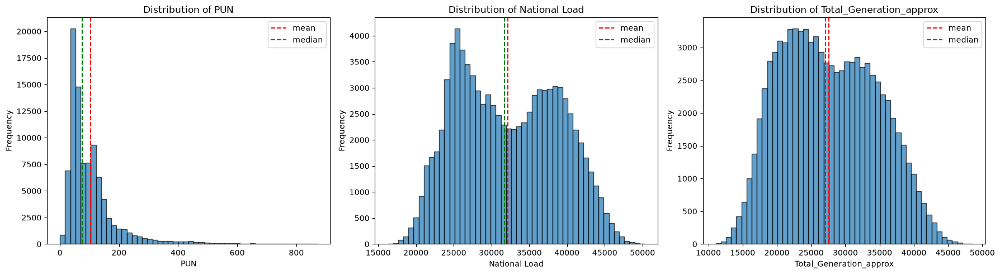

In [182]:
#create plot
fig, axes = plt.subplots(1, len(cols), figsize=(18, 5))

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=50, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label='mean')
    axes[i].axvline(df[col].median(), color='green', linestyle='--', label='median')
    axes[i].legend()

plt.tight_layout()
plt.show()

## 2.3. Time series analysis

In this section, since the project aim to analyze the relationship between Prices, Load and Generation, time series evolution of those variables are displayed during the ten-years time span.

### 2.3.1. Raw time series

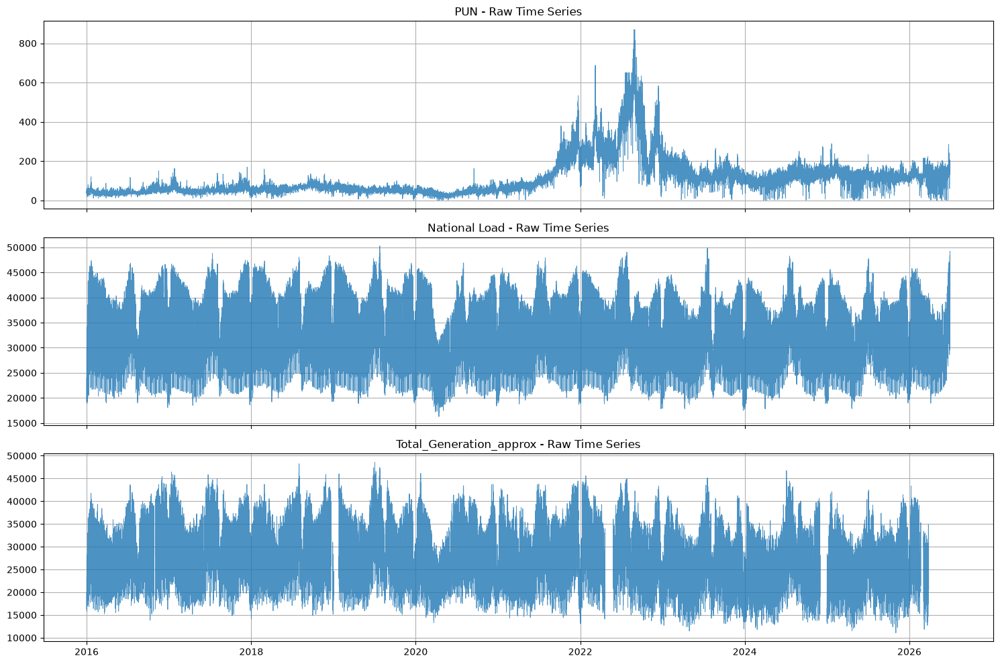

In [183]:
# plot graph
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col], linewidth=0.6, alpha=0.8)
    ax[i].set_title(f'{col} - Raw Time Series')
    ax[i].grid(True)

plt.tight_layout()
plt.show()

### 2.3.2. Rolling mean

To smooth short-term fluctuations in the hourly observations and highlight broader temporal patterns, a 24-hour rolling mean is calculated.

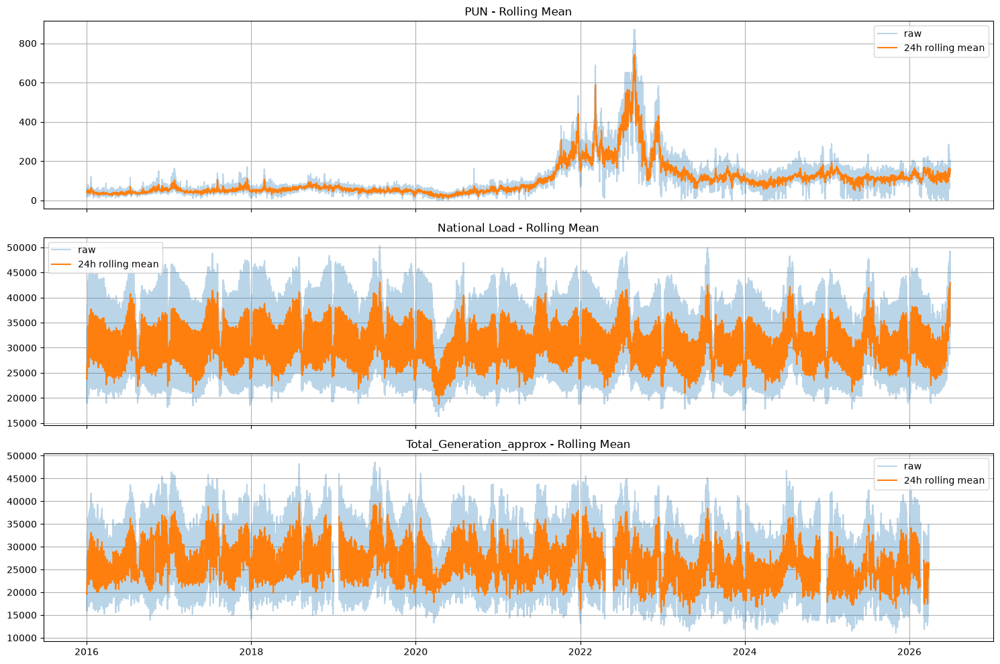

In [184]:
# define rolling window
window = 24  # 24h rolling window (1 day)

fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col], alpha=0.3, label='raw')
    ax[i].plot(df['datetime_UTC'], df[col].rolling(window).mean(), label='24h rolling mean')
    ax[i].set_title(f'{col} - Rolling Mean')
    ax[i].legend()
    ax[i].grid(True)

plt.tight_layout()
plt.show()

### 2.3.3. Volatility of first differences

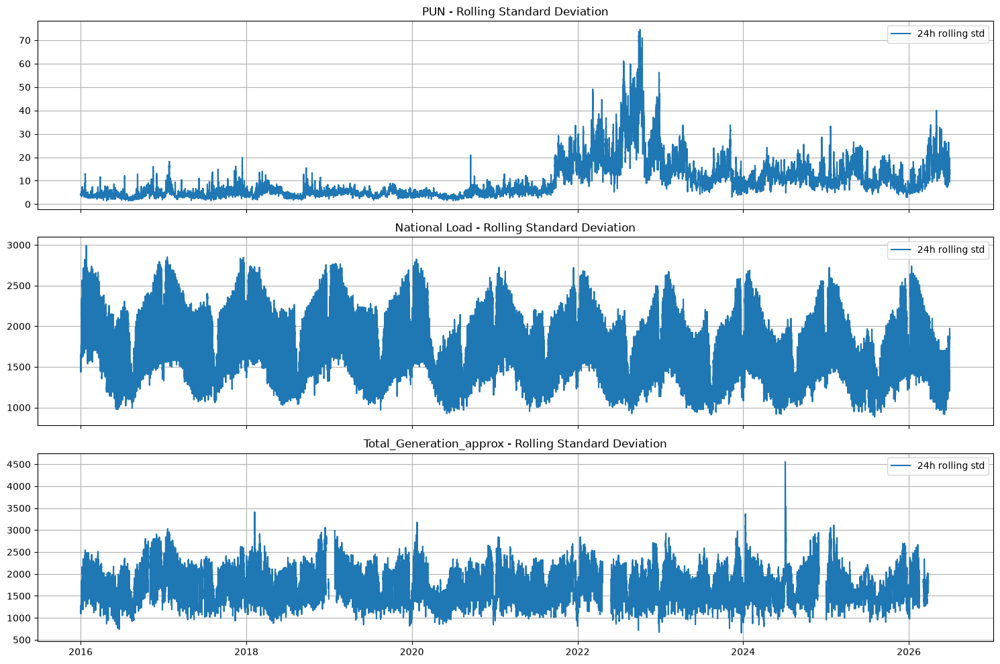

In [185]:
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, col in enumerate(cols):
    ax[i].plot(df['datetime_UTC'], df[col].diff().rolling(window).std(), label='24h rolling std')
    ax[i].set_title(f'{col} - Rolling Standard Deviation')
    ax[i].legend()
    ax[i].grid(True)

plt.tight_layout()
plt.show()

### 2.3.4. Daily prices and major market events

In [186]:
# convert hourly data in daily data
daily_prices = (
    df
    .set_index('datetime_UTC')[f'{price_col_name}']
    .resample('D')
    .mean()
)

In [187]:
# create event DF
events = pd.DataFrame({
    'Date': pd.to_datetime([
        '2021-07-01',
        '2021-12-01',
        '2022-02-24',
        '2022-08-01',
        '2022-09-26',
        '2023-05-01',
        '2024-12-12',
        '2025-07-01',
        '2026-03-01'
    ]),
    
    'Event': [
        'Tight LNG supply',
        'Low hydro and nuclear availability',
        'Russian invasion of Ukraine',
        'Low wind and nuclear availability',
        'Nord Stream sabotage',
        'Gas TTF normalization phase',
        'Dunkelflaute',
        'European Heatwave',
        'Hormuz crisis'
    ],
    
    'Ticker': [
       'E1',
       'E2',
       'E3',
       'E4',
       'E5',
       'E6',
       'E7',
       'E8',
       'E9',
    ],
    
    'Category': [
        'Energy-system shock',
        'Energy-system shock',
        'Geopolitical - Supply shocks',
        'Energy-system shock',
        'Geopolitical - Supply shocks',
        'Regime transition',
        'Energy-system shock',
        'Energy-system shock',
        'Geopolitical - Supply shocks'
    ]
})

# define label positions
events['level'] = [0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]

events

,Date,Event,Ticker,Category,level
0,2021-07-01,Tight LNG supply,E1,Energy-system shock,0.05
1,2021-12-01,Low hydro and nuclear availability,E2,Energy-system shock,0.05
2,2022-02-24,Russian invasion of Ukraine,E3,Geopolitical - Supply shocks,0.05
3,2022-08-01,Low wind and nuclear availability,E4,Energy-system shock,0.05
4,2022-09-26,Nord Stream sabotage,E5,Geopolitical - Supply shocks,0.05
5,2023-05-01,Gas TTF normalization phase,E6,Regime transition,0.05
6,2024-12-12,Dunkelflaute,E7,Energy-system shock,0.05
7,2025-07-01,European Heatwave,E8,Energy-system shock,0.05
8,2026-03-01,Hormuz crisis,E9,Geopolitical - Supply shocks,0.05


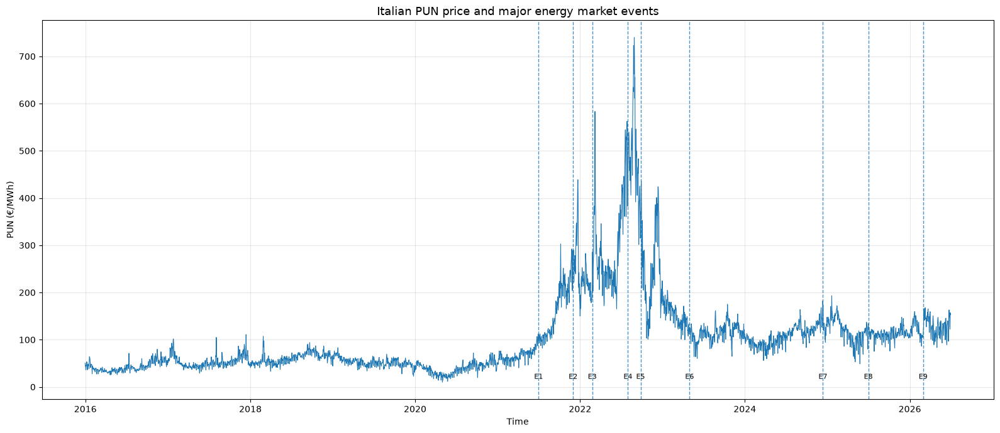

In [188]:
# display daily prices with significant events
fig, ax = plt.subplots(figsize=(16, 7))

# PUN time series
ax.plot(
    daily_prices.index,
    daily_prices.values,
    linewidth=0.8
)

# important events
for _, event in events.iterrows():
    # vertical line
    ax.axvline(
        event['Date'],
        linestyle='--',
        linewidth=1,
        alpha=0.8
    )

    # event label
    ax.text(
        event['Date'],
        event['level'],
        event['Ticker'],
        transform=ax.get_xaxis_transform(),
        rotation=0,
        ha='center',
        va='bottom',
        fontsize=8
    )

# labels and title
ax.set_title(
    'Italian PUN price and major energy market events',
    fontsize=13
)

ax.set_xlabel('Time')
ax.set_ylabel('PUN (€/MWh)')

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3.5. Evolution of the Italian generation mix
Monthly average generation by selected core technologies.  
Missing observations are retained as gaps, not replaced with zero.

In [189]:
# technologies included in the core mix
core_plot_cols = list(dict.fromkeys(res_core + fossil))

# work on copy and keep local timestamps for calendar-month aggregation
plot_df = df.copy()
plot_df["datetime_local"] = pd.to_datetime(
    plot_df["datetime_local"]
)

plot_df = (
    plot_df
    .sort_values("datetime_UTC")
    .set_index("datetime_local")
)

# monthly average generation (MW)
monthly_mean = (
    plot_df[core_plot_cols]
    .resample("MS")
    .mean()
)

# keep a monthly value only if at least 95% of expected hourly observations are available for that source
monthly_observed = (
    plot_df[core_plot_cols]
    .notna()
    .resample("MS")
    .sum()
)

monthly_expected = plot_df.resample("MS").size()

monthly_coverage = monthly_observed.div(
    monthly_expected, axis=0
)

monthly_mean = monthly_mean.where(
    monthly_coverage >= 0.95
)

# convert to long format for Plotly
plot_long = (
    monthly_mean
    .rename_axis("Month")
    .reset_index()
    .melt(
        id_vars="Month",
        var_name="Technology",
        value_name="Monthly average generation (MW)"
    )
)

# interactive stacked area chart
fig = px.area(
    plot_long,
    x="Month",
    y="Monthly average generation (MW)",
    color="Technology",
    title=(
        "Italian Electricity Generation Mix "
        "(2016–June 2026)"
    ),
    labels={
        "Month": "Month",
        "Monthly average generation (MW)": "Average output (MW)",
        "Technology": "Technology"
    }
)

# preserve gaps where monthly data coverage is insufficient
fig.update_traces(connectgaps=False)

fig.update_layout(
    hovermode="x unified",
    legend_title_text="Technology",
    legend=dict(
        itemclick="toggle",
        itemdoubleclick="toggleothers"
    ),
    xaxis=dict(
        rangeslider=dict(visible=True)
    )
)

fig.show()

## 2.4. Relationship analysis

### 2.4.1. Pearson correlation matrix

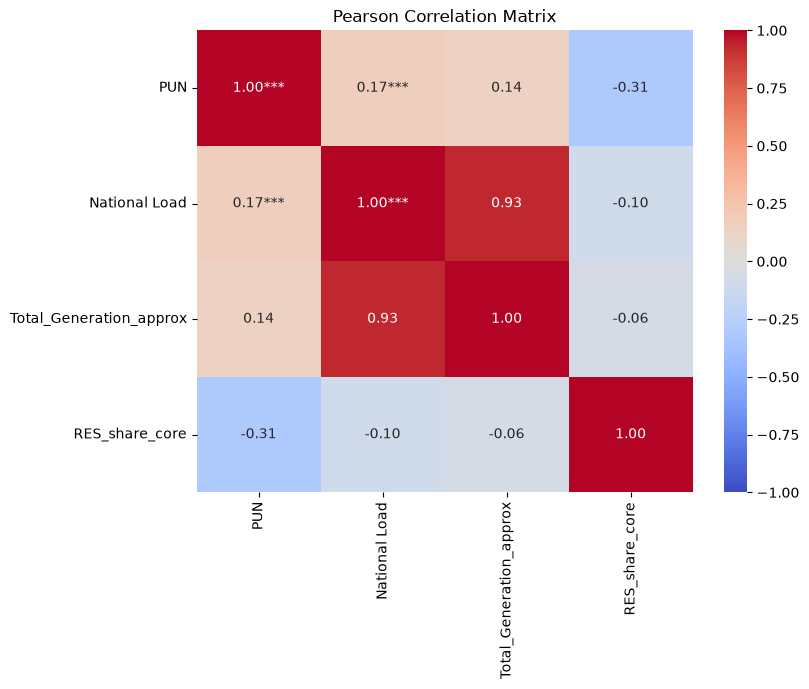

In [190]:
# main variables
corr_cols_main = [f'{price_col_name}', f'{load_col_name}', 'Total_Generation_approx', 'RES_share_core']

# correlation matrix
main_corr_matrix = df[corr_cols_main].corr()

# P-value matrix
p_matrix = pd.DataFrame(
    index=corr_cols_main,
    columns=corr_cols_main,
    dtype=float
)

for col1 in corr_cols_main:
    for col2 in corr_cols_main:
        r, p = pearsonr(df[col1], df[col2])
        p_matrix.loc[col1, col2] = p

# create annotations
annotations = main_corr_matrix.copy().astype(str)

for row in corr_cols_main:
    for col in corr_cols_main:
        r = main_corr_matrix.loc[row, col]
        p = p_matrix.loc[row, col]

        if p < 0.001:
            stars = '***'
        elif p < 0.01:
            stars = '**'
        elif p < 0.05:
            stars = '*'
        else:
            stars = ''

        annotations.loc[row, col] = f'{r:.2f}{stars}'

# heatmap correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    main_corr_matrix,
    annot=annotations,
    fmt='',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Pearson Correlation Matrix')
plt.show()

*p-value < 0.05  
**p-value < 0.01  
***p-value < 0.001  

In [191]:
# detailed variables
corr_cols_detailed = generation_approx_cols
corr_cols_detailed.append(f'{price_col_name}')
corr_cols_detailed.append(f'{load_col_name}')
corr_cols_detailed

['Biomass',
 'Fossil Coal-derived gas',
 'Fossil Gas',
 'Fossil Hard coal',
 'Fossil Oil',
 'Geothermal',
 'Hydro Run-of-river and poundage',
 'Hydro Water Reservoir',
 'Other',
 'Solar',
 'Waste',
 'Wind Onshore',
 'Wind Offshore',
 'PUN',
 'National Load']

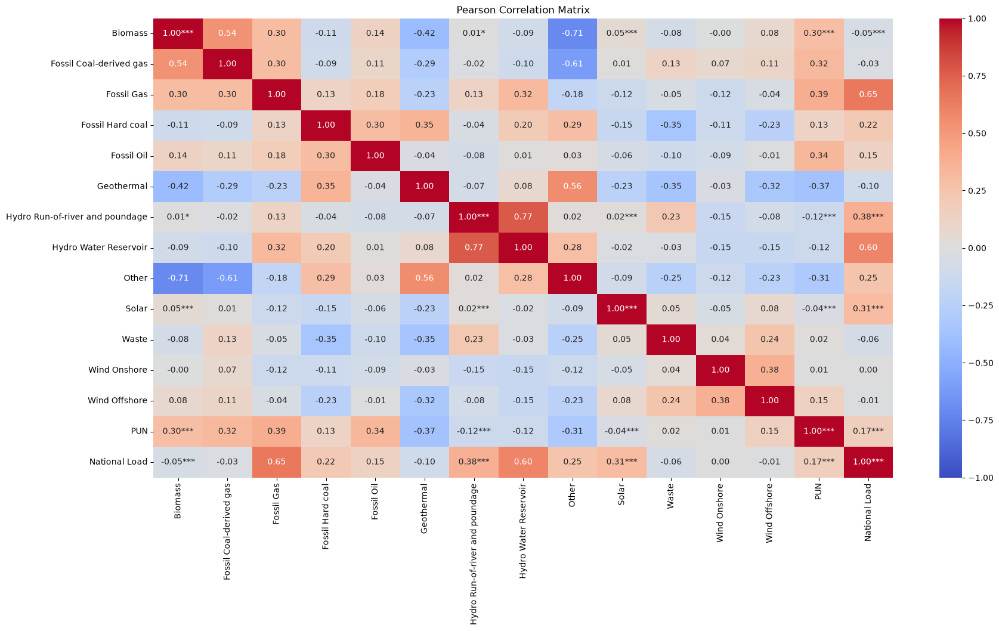

In [192]:
# correlation matrix
detailed_corr_matrix = df[corr_cols_detailed].corr()

# P-value matrix
p_matrix = pd.DataFrame(
    index=corr_cols_detailed,
    columns=corr_cols_detailed,
    dtype=float
)

for col1 in corr_cols_detailed:
    for col2 in corr_cols_detailed:
        r, p = pearsonr(df[col1], df[col2])
        p_matrix.loc[col1, col2] = p

# create annotations
annotations = detailed_corr_matrix.copy().astype(str)

for row in corr_cols_detailed:
    for col in corr_cols_detailed:
        r = detailed_corr_matrix.loc[row, col]
        p = p_matrix.loc[row, col]

        if p < 0.001:
            stars = '***'
        elif p < 0.01:
            stars = '**'
        elif p < 0.05:
            stars = '*'
        else:
            stars = ''

        annotations.loc[row, col] = f'{r:.2f}{stars}'

# heatmap correlation matrix
plt.figure(figsize=(20, 10))

sns.heatmap(
    detailed_corr_matrix,
    annot=annotations,
    fmt='',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Pearson Correlation Matrix')
plt.show()

### 2.4.2. Correlation significance and sample coverage

In [193]:
# main variables p-value matrix
p_matrix = pd.DataFrame(
    index=corr_cols_main,
    columns=corr_cols_main,
    dtype=float
)

for col1 in corr_cols_main:
    for col2 in corr_cols_main:
        r, p = pearsonr(df[col1], df[col2])
        p_matrix.loc[col1, col2] = p
    
p_matrix

,PUN,National Load,Total_Generation_approx,RES_share_core
PUN,0.0,0.0,NaN,NaN
National Load,0.0,0.0,NaN,NaN
Total_Generation_approx,NaN,NaN,NaN,NaN
RES_share_core,NaN,NaN,NaN,NaN


NAN p-values are affected by NAN values in generation.  
Following correction is implemented for the detailed technologies.

In [194]:
# detailed variables p-value matrix
p_values = pd.DataFrame(
    np.nan, index=corr_cols_detailed, columns=corr_cols_detailed
)

n_pairs = pd.DataFrame(
    0, index=corr_cols_detailed, columns=corr_cols_detailed
)

for i, col1 in enumerate(corr_cols_detailed):
    for col2 in corr_cols_detailed[i + 1:]:

        pair = (
            df[[col1, col2]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        n = len(pair)

        n_pairs.loc[col1, col2] = n
        n_pairs.loc[col2, col1] = n

        if (
            n >= 3
            and pair[col1].nunique() > 1
            and pair[col2].nunique() > 1
        ):
            _, p = pearsonr(pair[col1], pair[col2])

            p_values.loc[col1, col2] = p
            p_values.loc[col2, col1] = p

p_values

,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,Geothermal,Hydro Run-of-river and poundage,Hydro Water Reservoir,Other,Solar,Waste,Wind Onshore,Wind Offshore,PUN,National Load
Biomass,NaN,0.000000e+00,0.000000e+00,2.068323e-227,0.000000e+00,0.000000e+00,2.266824e-02,5.454152e-178,0.000000e+00,2.431805e-54,2.421692e-112,9.922317e-01,1.464883e-128,0.000000e+00,4.508243e-48
Fossil Coal-derived gas,0.000000e+00,NaN,0.000000e+00,6.531003e-180,1.261222e-220,0.000000e+00,2.072645e-11,9.293683e-212,0.000000e+00,7.900637e-03,0.000000e+00,7.205195e-102,8.948233e-259,0.000000e+00,1.674451e-16
Fossil Gas,0.000000e+00,0.000000e+00,NaN,1.549294e-315,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.051592e-294,6.366622e-42,5.704422e-285,1.171341e-38,0.000000e+00,0.000000e+00
Fossil Hard coal,2.068323e-227,6.531003e-180,1.549294e-315,NaN,0.000000e+00,0.000000e+00,2.730491e-32,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.032912e-257,0.000000e+00,3.043444e-321,0.000000e+00
Fossil Oil,0.000000e+00,1.261222e-220,0.000000e+00,0.000000e+00,NaN,4.694376e-31,2.993961e-120,1.043420e-02,3.031012e-18,6.388222e-74,1.246993e-210,1.393536e-146,3.789538e-04,0.000000e+00,0.000000e+00
Geothermal,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.694376e-31,NaN,3.737348e-104,2.293958e-140,0.000000e+00,0.000000e+00,0.000000e+00,5.715992e-22,0.000000e+00,0.000000e+00,1.081624e-183
Hydro Run-of-river and poundage,2.266824e-02,2.072645e-11,0.000000e+00,2.730491e-32,2.993961e-120,3.737348e-104,NaN,0.000000e+00,1.213877e-12,2.349853e-07,0.000000e+00,0.000000e+00,9.591292e-130,1.116074e-315,0.000000e+00
Hydro Water Reservoir,5.454152e-178,9.293683e-212,0.000000e+00,0.000000e+00,1.043420e-02,2.293958e-140,0.000000e+00,NaN,0.000000e+00,5.968742e-14,4.065575e-15,0.000000e+00,0.000000e+00,9.623705e-310,0.000000e+00
Other,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.031012e-18,0.000000e+00,1.213877e-12,0.000000e+00,NaN,2.931743e-170,0.000000e+00,1.327477e-299,0.000000e+00,0.000000e+00,0.000000e+00
Solar,2.431805e-54,7.900637e-03,8.051592e-294,0.000000e+00,6.388222e-74,0.000000e+00,2.349853e-07,5.968742e-14,2.931743e-170,NaN,2.028996e-48,8.714871e-49,8.554071e-143,2.615668e-27,0.000000e+00


# 3. Econometric Analysis

## 3.1. Econometric framework and model specification

### Research objective
The econometric analysis investigates the relationship between Italian wholesale electricity prices and the conditions of the national electricity system over the period January 2016–June 2026.  
The main objective is to examine whether the association between renewable generation and electricity prices varies across market regimes, and whether demand conditions and generation composition provide additional explanatory information.  
The analysis is exploratory and observational. Estimated coefficients are interpreted as conditional associations and do not, by themselves, identify causal effects or the technology setting the marginal price.

### Dependent variable
The dependent variable is the Italian national wholesale electricity price (`PUN`), expressed in €/MWh.

### Explanatory variables
The analysis considers the following groups of explanatory variables:
- Renewable penetration (`RES_share_core`): the share of selected renewable technologies in the defined core generation mix.
- Market regimes (`Period`): predefined categories used to compare different market conditions.
- National load (`National Load`): electricity demand at national level.
- Residual demand (`Residual_Demand_core`): national load minus the selected renewable generation aggregate.
- Generation technology groups: selected renewable technologies and observed fossil generation, including gas-fired generation.
- Calendar controls: local hour, day of the week and calendar month.
- Gas price: a potential extension, conditional on the availability of a suitable historical price series.

### Model strategy
The analysis proceeds in stages:
1. Baseline model with market-regime and calendar controls.
2. Renewable penetration model.
3. Regime-dependent renewable relationship, including interactions.
4. Load and combined renewable-load specifications.
5. Residual-demand specification as an alternative representation of system conditions.
6. Generation-mix specifications to compare technology groups.
7. Dynamic models incorporating lagged electricity prices and, where justified, lagged explanatory variables.

A gas-price model is considered separately because gas-fired generation and the price of natural gas represent different mechanisms.

### Estimation and inference
The static models are estimated using Ordinary Least Squares (OLS). Heteroscedasticity and residual autocorrelation are examined through diagnostic tests and residual analysis.  
Heteroscedasticity and autocorrelation consistent (HAC) standard errors are used where appropriate for statistical inference. HAC standard errors do not remove residual autocorrelation or replace the specification of a dynamic model.  
Model comparisons account for the estimation sample and the number of parameters. Differences in explanatory power are interpreted alongside coefficient estimates, uncertainty and residual diagnostics.

### Limitations
Generation data contain some missing observations and certain technology categories have classification or coverage limitations.  
Aggregate generation measures and residual demand are therefore interpreted according to their explicit definitions.  
The analysis does not directly identify hourly marginal-price-setting technologies. This would require additional market or dispatch data.

_Table 1: The summary of the models applied_
| Code | Model              |
|------|--------------------|
| M1   | Baseline           | 
| M2   | Renewables         | 
| M3   | Regime             |   
| M4   | Load               |
| M5   | Residual Load      |
| M6   | Type og technology |

## 3.2. Static regression models

In [195]:
# calendar controls
df['local_month'] = df['datetime_local'].dt.month
df['day_of_week'] = df['datetime_local'].dt.dayofweek

calendar_terms = (
    'C(local_hour) + '
    'C(day_of_week) + '
    'C(local_month)'
)

# model specifications
formulas = {
    'M0_Baseline': (
        f'PUN ~ C(Period) + {calendar_terms}'
    ),

    'M1_Renewables': (
        f'PUN ~ RES_share_core + C(Period) '
        f'+ {calendar_terms}'
    ),

    'M1b_Renewables_Regime_Interaction': (
        f'PUN ~ RES_share_core * C(Period) '
        f'+ {calendar_terms}'
    ),

    'M2_Load': (
        f'PUN ~ Q("National Load") + C(Period) '
        f'+ {calendar_terms}'
    ),

    'M3_Residual_Demand': (
        f'PUN ~ Residual_Demand_core + C(Period) '
        f'+ {calendar_terms}'
    )
}

### 3.2.1. Baseline model

-----------------[WIP]-----------------

#### 2.5.1 Baseline model - Bivariate relationship between renewable penetration and prices

##### 2.5.1.1. Simple Model implementation

In [196]:
data = df
data

,datetime_UTC,datetime_local,local_hour,PUN,National Load,Biomass,Fossil Coal-derived gas,Fossil Gas,Fossil Hard coal,Fossil Oil,...,Generation_approx_missing_components,Generation_approx_completeness_pct,Total_Generation_core,Core_Generation_Missing_Components,Core_Generation_Completeness_pct,RES_share_core,Residual_Demand_core,day_of_week,local_month,Period
0,2015-12-31 23:00:00+00:00,2016-01-01 00:00:00+01:00,0,50.41211,23927.233,220.00,241.00,5588.00,1686.00,542.00,...,0,100.000000,10732.00,0,100.0,0.249255,21252.233,4,1,Pre_crises
1,2016-01-01 00:00:00+00:00,2016-01-01 01:00:00+01:00,1,44.76435,22517.279,216.00,241.00,5034.00,1719.00,519.00,...,0,100.000000,9898.00,0,100.0,0.240958,20132.279,4,1,Pre_crises
2,2016-01-01 01:00:00+00:00,2016-01-01 02:00:00+01:00,2,40.01613,21354.678,217.00,241.00,4486.00,1728.00,530.00,...,0,100.000000,9284.00,0,100.0,0.247630,19055.678,4,1,Pre_crises
3,2016-01-01 02:00:00+00:00,2016-01-01 03:00:00+01:00,3,37.92076,20219.874,216.00,241.00,4275.00,1727.00,467.00,...,0,100.000000,8888.00,0,100.0,0.245050,18041.874,4,1,Pre_crises
4,2016-01-01 03:00:00+00:00,2016-01-01 04:00:00+01:00,4,35.77287,19229.221,215.00,241.00,3926.00,1658.00,426.00,...,0,100.000000,8393.00,0,100.0,0.255213,17087.221,4,1,Pre_crises
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92010,2026-06-30 17:00:00+00:00,2026-06-30 19:00:00+02:00,19,204.10622,48437.300,712.50,641.50,26968.25,394.75,155.75,...,1,92.307692,38320.25,0,100.0,0.265134,38277.300,1,6,Post_crises
92011,2026-06-30 18:00:00+00:00,2026-06-30 20:00:00+02:00,20,198.16000,47383.500,714.00,661.75,27442.75,396.50,156.00,...,1,92.307692,37810.50,0,100.0,0.242089,38230.000,1,6,Post_crises
92012,2026-06-30 19:00:00+00:00,2026-06-30 21:00:00+02:00,21,182.03250,45951.100,716.50,676.50,27084.00,392.25,156.00,...,1,92.307692,37408.25,0,100.0,0.243248,36851.600,1,6,Post_crises
92013,2026-06-30 20:00:00+00:00,2026-06-30 22:00:00+02:00,22,173.30306,43204.200,710.25,647.50,26959.75,365.75,158.25,...,1,92.307692,36016.25,0,100.0,0.218929,35319.200,1,6,Post_crises


In [197]:
# model variables
VAR_X = 'RES_share_core'
VAR_Y = 'PUN'

formula = f'{VAR_Y} ~ {VAR_X}'

model = smf.ols(formula, data=data).fit()
print(f'\nLinear Regression Model - Prices and Renewables (2021 - 2026)\n')
print(model.summary())


Linear Regression Model - Prices and Renewables (2021 - 2026)

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     9400.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:12:50   Log-Likelihood:            -5.2323e+05
No. Observations:               89097   AIC:                         1.046e+06
Df Residuals:                   89095   BIC:                         1.046e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [198]:
# get params for line equation
params = model.params

# x values
ax_x = f'{VAR_X}'
x = np.linspace(0, 1, 100)

# coefficients
b0 = model.params['Intercept']
b1 = model.params[f'{VAR_X}']

# f lines
y_d_0 = b0 + b1 * x 


In [199]:
fig = px.scatter(
    data, 
    x= f'{VAR_X}', 
    y=f'{VAR_Y}', 
    hover_data={
        f'{VAR_X}': True,
        f'{VAR_Y}': True, 
        'datetime_UTC': True
    }, 
    opacity=0.05
)

fig.add_trace(
    go.Scatter(
        x=x,
        y=y_d_0,
        mode='lines',
        name='Power Prices',
        line=dict(width=4)
    )
)

fig.update_layout(
    title='Linear Regression (OLS)',
    xaxis_title='Renewables share',
    yaxis_title='Prices',
    template='simple_white'
)

fig.show()

##### 2.5.1.2. Simple Model evaluation

Before commenting the regression results, it is necessary to execute basic tests on:
1. Heteroscedasticity
2. Autocorrelation of the residuals


##### 1. Heteroscedasticity - Breusch-Pagan test

In [200]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Breusch-Pagan test
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

bp_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Pagan Test')
for label, value in zip(bp_labels, bp_test):
    print(f'{label}: {value:.4f}')


Breusch-Pagan Test
LM Statistic: 2417.7868
LM p-value: 0.0000
F Statistic: 2485.1716
F p-value: 0.0000


p-value < 0.05 indicates that the null hypothesis (homoschedasticity) is refused and therefore, that there is evidence of heteroscedasticity.

##### 2. Residuals Autocorrelation

In [201]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Breusch-Godfrey test
bg_test = acorr_breusch_godfrey(
    model,
    nlags=24    # 24 hrs lag correlation
)

bg_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Godfrey Test')
for label, value in zip(bg_labels, bg_test):
    print(f'{label}: {value:.4f}')


Breusch-Godfrey Test
LM Statistic: 87846.8287
LM p-value: 0.0000
F Statistic: 260784.4166
F p-value: 0.0000


H0: no autocorrelation until the lag taken into consideration  
vs  
H1: autocorrelation

p-value < 0.05 indicates the residuals autocorrelation.


In [202]:
# Durbin-Watson test check
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(model.resid)

print(f'\nDurbin-Watson statistic: {dw:.4f}')


Durbin-Watson statistic: 0.0227


Durbin-Watson value 0.04 < 2 indicates a strong positive autocorrelation of the residuals. This result is consistent with former Breusch-Godfrey test which confirms autocorrelation.

Having these results about the former linear regression model, the same model is displayed with HAC covariance in ordere to have more accurate data on standard errores and significance of the coefficients.

##### 2.5.1.3. Model correction

In [203]:
# hac model
bivariate_hac_model = smf.ols(
    formula, 
    data=data
).fit(
    cov_type='HAC', 
    cov_kwds={
        'maxlags':24
    }
)

print(f'\nLinear Regression Model - Prices and Renewables (2021 - 2026)\n')
print(bivariate_hac_model.summary())


Linear Regression Model - Prices and Renewables (2021 - 2026)

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     576.6
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          5.34e-127
Time:                        18:12:52   Log-Likelihood:            -5.2323e+05
No. Observations:               89097   AIC:                         1.046e+06
Df Residuals:                   89095   BIC:                         1.046e+06
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------

#### 2.5.2. Regime-dependent relationship

##### 2.5.2.1. Model implementation

In [204]:
# interaction
regime_interaction_model = smf.ols(
    f'{price_col_name} ~ RES_share_core * Period',
    data=data
).fit()

print(regime_interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                 2.225e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:12:52   Log-Likelihood:            -4.8267e+05
No. Observations:               89097   AIC:                         9.654e+05
Df Residuals:                   89089   BIC:                         9.654e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

##### 5.2.2. Model evaluation

This model will be evaluated by: 
1. Heteroscedasticity
2. Residuals autocorrelation
3. Multicollinearity

##### 1. Heteroscedasticity

In [205]:
# Breusch-Pagan test
bp_test = het_breuschpagan(
    regime_interaction_model.resid,
    regime_interaction_model.model.exog
)

bp_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Pagan Test')
for label, value in zip(bp_labels, bp_test):
    print(f'{label}: {value:.4f}')


Breusch-Pagan Test
LM Statistic: 15210.3390
LM p-value: 0.0000
F Statistic: 2619.9856
F p-value: 0.0000


#### 2. Residuals autocorrelation

In [206]:
# Breusch-Godfrey test
bg_test = acorr_breusch_godfrey(
    regime_interaction_model,
    nlags=24    # 24 hrs lag correlation
)

bg_labels = [
    'LM Statistic',
    'LM p-value',
    'F Statistic',
    'F p-value'
]

print('\nBreusch-Godfrey Test')
for label, value in zip(bg_labels, bg_test):
    print(f'{label}: {value:.4f}')


Breusch-Godfrey Test
LM Statistic: 86189.2277
LM p-value: 0.0000
F Statistic: 109998.9202
F p-value: 0.0000


In [207]:
# Durbin-Watson test check
dw = durbin_watson(regime_interaction_model.resid)

print(f'\nDurbin-Watson statistic: {dw:.4f}')


Durbin-Watson statistic: 0.0534


#### 3. Multicollinearity

In [208]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = regime_interaction_model.model.exog
feature_names = regime_interaction_model.model.exog_names

vif = pd.DataFrame({
    'Variable': feature_names,
    'VIF': [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

print('\nVariance Inflation Factors')
print(vif)


Variance Inflation Factors
                                 Variable        VIF
0                               Intercept   1.000000
1                 Period[T.Demand_crisis]  16.617709
2                 Period[T.Supply_crisis]  12.260143
3                   Period[T.Post_crises]  12.966926
4                          RES_share_core   3.183126
5  RES_share_core:Period[T.Demand_crisis]  16.487145
6  RES_share_core:Period[T.Supply_crisis]  10.933232
7    RES_share_core:Period[T.Post_crises]  15.092297


#### 5.2.3. Model correction

In [209]:
# robust model to heteroskedasticity and autocorrelation
regime_robust_model = smf.ols(
     f'{price_col_name} ~ RES_share_core * Period',
    data=data
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags':24}
)

print(regime_robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    PUN   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     2551.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:12:54   Log-Likelihood:            -4.8267e+05
No. Observations:               89097   AIC:                         9.654e+05
Df Residuals:                   89089   BIC:                         9.654e+05
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                                             coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [211]:
# model params for visualization
params = regime_robust_model.params

# x values
x = np.linspace(
    data['RES_share_core'].min(),
    data['RES_share_core'].max(),
    100
)

# coefficients
b0 = regime_robust_model.params['Intercept']
b1 = regime_robust_model.params['RES_share_core']
b2 = regime_robust_model.params['Period[T.Post_crises]']
b3 = regime_robust_model.params['Period[T.Post_crises]']
b4 = regime_robust_model.params['RES_share_core:Period[T.Post_crises]']
b5 = regime_robust_model.params['RES_share_core:Period[T.Post_crises]']

# f lines
y_shock = b0 + b1 * x
y_post = b0 + b1 * x + b2 + b4 * x
y_pre = b0 + b1 * x + b3 + b5 * x

In [212]:
# extensions of x to see what happens when renewables is 0% and 100%
x_ext = np.linspace(0, 1, 100)

fig = px.scatter(
    data,
    x=f'{VAR_X}',
    y=f'{VAR_Y}',
    color='Period',
    trendline='ols', 
    opacity=0.05
)

results = px.get_trendline_results(fig)

for _, row in results.iterrows():
    regime = row['Period']
    regime_robust_model = row['px_fit_results']

    intercept = regime_robust_model.params[0]
    slope = regime_robust_model.params[1]

    y_ext = intercept + slope * x_ext

    fig.add_trace(
        go.Scatter(
            x=x_ext,
            y=y_ext,
            mode='lines',
            name=f'{regime} extension',
            line=dict(
                dash='dash',
                width=2
            ),
            hovertemplate=(
                f'Regime: {regime}<br>'
                'Renewables: %{x:.2f}<br>'
                'Predicted Price: %{y:.2f}'
                '<extra></extra>'
            )
        )
    )

fig.add_vline(
    x=0,
    line_dash='dot',
    line_color='black'
)